11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch: 1000
Epoch: 2000
Epoch: 3000
Epoch: 4000
Epoch: 5000


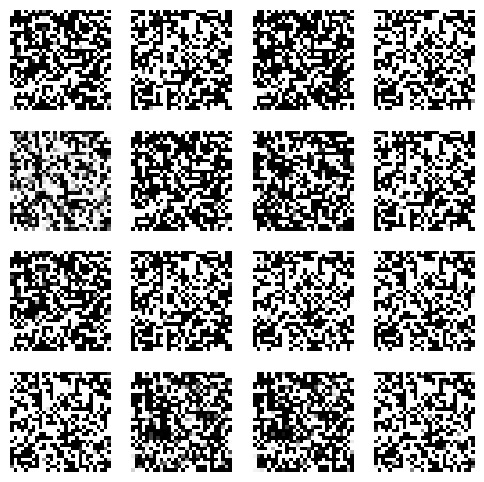

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Reshape, Flatten, LeakyReLU

(X_train, _), (_, _) = tf.keras.datasets.mnist.load_data()
X_train = (X_train.astype('float32') - 127.5) / 127.5
X_train = X_train.reshape(-1, 784)

generator = Sequential([
    Dense(128, input_dim=100),
    LeakyReLU(negative_slope=0.2),
    Dense(256),
    LeakyReLU(negative_slope=0.2),
    Dense(784, activation='tanh'),
    Reshape((28, 28))
])

discriminator = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256),
    LeakyReLU(negative_slope=0.2),
    Dense(1, activation='sigmoid')
])

discriminator.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])

discriminator.trainable = False

gan = Sequential([generator, discriminator])
gan.compile(optimizer='adam', loss='binary_crossentropy')

discriminator.trainable = True

for epoch in range(5000):
    idx = np.random.randint(0, X_train.shape[0], 64)
    real_images = X_train[idx].reshape(-1, 28, 28)

    noise = np.random.normal(0, 1, (64, 100))
    fake_images = generator.predict(noise, verbose=0)

    discriminator.train_on_batch(real_images, np.ones((64, 1)))
    discriminator.train_on_batch(fake_images, np.zeros((64, 1)))

    noise = np.random.normal(0, 1, (64, 100))
    gan.train_on_batch(noise, np.ones((64, 1)))

    if (epoch + 1) % 1000 == 0:
        print("Epoch:", epoch + 1)

noise = np.random.normal(0, 1, (16, 100))
generated_images = generator.predict(noise, verbose=0)

plt.figure(figsize=(6, 6))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images[i], cmap='gray')
    plt.axis('off')

plt.show()